# **Mini-assignment 1: Simulating the Sampling Distributions $\chi^2$, $t$, and $F$.**

Prove by simulation:

i) $\chi^2$-distribution: the statistic $\dfrac{(n-1)S^2}{\sigma^2}$, where $S^2 = \dfrac{1}{n-1}\sum_{i=1}^{n}(X_i - \bar{X})^2$ and $X_i \sim \mathcal{N}(\mu, \sigma^2)$, is $\chi^2$-distributed with $\text{df}=n-1$.

ii)Student's $t$-distribution: the statistic $\sqrt{n}\left(\dfrac{\bar{X}-\mu}{S}\right)$, where the $X_i$'s are such that $X_i \sim \mathcal{N}(\mu, \sigma^2)$ and $S^2 = \dfrac{1}{n-1}\sum_{i=1}^{n}(X_i-\bar{X})^2$, follows a $t$-distribution with $\text{df}=n-1$ (set $n=5$ for the simulation).

iii)$F$-distribution: the statistic $F = \dfrac{W_1/\text{df}_1}{W_2/\text{df}_2}$, where $W_1$ and $W_2$ are independent $\chi^2$-distributed random variables with degrees of freedom $\text{df}_1=n_1-1$ and $\text{df}_2=n_2-1$ respectively, has an $F$-distribution with $\text{dfn}=\text{df}_1$ and $\text{dfd}=\text{df}_2$.

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

## **i. The $\chi^2-$distribution.**

We consider $S^2 = \dfrac{1}{n-1}\sum_{i=1}^{n}(X_i - \bar{X})^2$, where $X_i \sim \mathcal{N}(\mu, \sigma^2)$. We simulate $N$ independent $n$-samples, compute $\dfrac{(n-1)S^2}{\sigma^2}$ for each of them, and compare the resulting empirical distribution to $\chi^2_{\text{df}=n-1}$.

In [14]:

mu, sigma = 5, 3   # population mean and sd, I choose it arbirarly
n = 10             # sample size
N = 100000         # number of simulated n-samples

np.random.seed(12345) # Setting a seed for reproducibility.
X = np.random.normal(loc=mu, scale=sigma, size=n * N).reshape(n, N) # n x N array; each column is one n-sample.

S2 = X.var(axis=0, ddof=1)          # sample variance of each of the N samples.
chi2_stat = (n - 1) * S2 / sigma**2 # the statistic (n-1)S^2/sigma^2 for each sample.

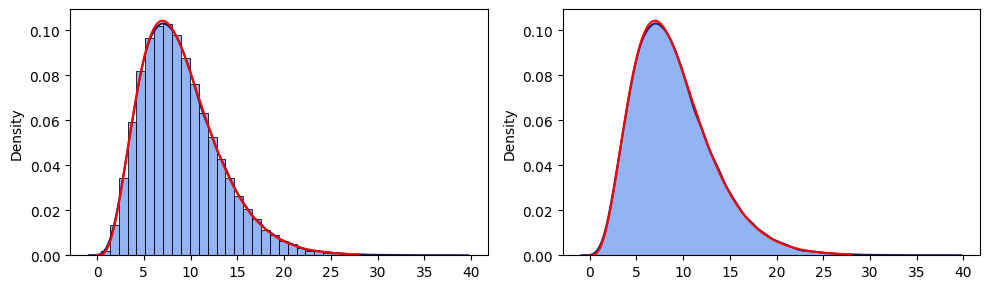

In [15]:
fig, ax = plt.subplots(1, 2)
plt.rcParams["figure.figsize"] = [10, 3]
plt.rcParams["figure.autolayout"] = True

# Empirical density of the simulated statistic.
sns.histplot(x=chi2_stat, stat='density', bins=40, alpha=.7, color='cornflowerblue', ax=ax[0])
sns.kdeplot(x=chi2_stat, color='midnightblue', ax=ax[0])

# Theoretical chi2(df=n-1) density.
x_values = np.linspace(0, np.quantile(chi2_stat, .999), 1000)
y_values = sp.stats.chi2.pdf(x=x_values, df=n - 1)
sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[0])

sns.kdeplot(x=chi2_stat, color='cornflowerblue', ax=ax[1], fill=True, alpha=.7)
sns.kdeplot(x=chi2_stat, color='midnightblue', ax=ax[1])
sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[1]);

In [16]:
# Comparing empirical vs theoretical moments (mean=df, variance=2*df for a chi2_df).
(chi2_stat.mean(), n - 1), (chi2_stat.var(ddof=1), 2 * (n - 1))

((np.float64(9.003765560487253), 9), (np.float64(18.055539505111604), 18))

The empirical density (blue) overlays the theoretical $\chi^2_{\text{df}=n-1}$ density (red) almost perfectly, and the empirical mean and variance of the simulated statistic are very close to the theoretical values $\text{df}=n-1$ and $2\,\text{df}=2(n-1)$.

## **ii. Student's $t-$distribution.**

We now draw $N$ independent $n$-samples, with $n=5$, and we compute $\sqrt{n}\left(\dfrac{\bar{X}-\mu}{S}\right)$ for each of them, and compare the resulting empirical distribution to $t_{\text{df}=n-1}$.

In [17]:
mu, sigma = 5, 3   # population mean and sd, I choose them arbitrarly
n = 5              # sample size
N = 100000         # number of simulated n-samples

np.random.seed(12345)
X = np.random.normal(loc=mu, scale=sigma, size=n * N).reshape(n, N) # n x N array; each column is one n-sample.

xbar = X.mean(axis=0)          # sample mean of each of the N samples.
S = X.std(axis=0, ddof=1)      # sample sd of each of the N samples.
t_stat = np.sqrt(n) * (xbar - mu) / S # the statistic for each sample.

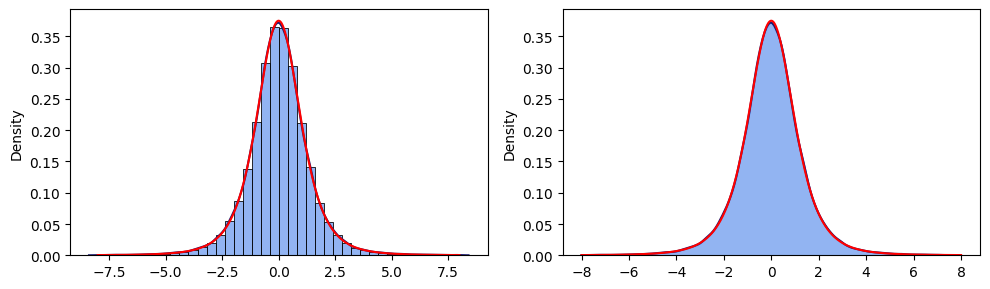

In [18]:
fig, ax = plt.subplots(1, 2)
plt.rcParams["figure.figsize"] = [10, 3]
plt.rcParams["figure.autolayout"] = True

t_stat_clipped = t_stat[(t_stat > -8) & (t_stat < 8)] # clipping a few extreme values, for a nicer-looking plot.

# Empirical density of the simulated statistic.
sns.histplot(x=t_stat_clipped, stat='density', bins=40, alpha=.7, color='cornflowerblue', ax=ax[0])
sns.kdeplot(x=t_stat_clipped, color='midnightblue', ax=ax[0])

# Theoretical t(df=n-1) density.
x_values = np.linspace(-8, 8, 1000)
y_values = sp.stats.t.pdf(x=x_values, df=n - 1)
sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[0])

sns.kdeplot(x=t_stat_clipped, color='cornflowerblue', ax=ax[1], fill=True, alpha=.7, clip=[-8, 8])
sns.kdeplot(x=t_stat_clipped, color='midnightblue', ax=ax[1], clip=[-8, 8])
sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[1]);

In [19]:
# Comparing empirical vs theoretical moments (mean=0, variance=df/(df-2) for df=n-1>2).
(t_stat.mean(), 0), (t_stat.var(ddof=1), (n - 1) / (n - 1 - 2))

((np.float64(-0.0011245271288322476), 0),
 (np.float64(2.0072925262156485), 2.0))

Again, the empirical density (blue) matches the theoretical $t_{\text{df}=n-1}$ density (red) very closely and the empirical mean and variance are close to $0$ and $\dfrac{n-1}{n-3}$.

## **iii. The $F-$distribution.**

To recreate the two independent $\chi^2$-variables we use part i). We create $W_1 = \dfrac{(n_1-1)S_1^2}{\sigma_1^2}$ and $W_2 = \dfrac{(n_2-1)S_2^2}{\sigma_2^2}$  from two independent normal samples of sizes $n_1$ and $n_2$; $W_1$ and $W_2$ are then independent $\chi^2-$distributed random variables with $\text{df}_1=n_1-1$ and $\text{df}_2=n_2-1$ degrees of freedom, respectively. We compute $F=\dfrac{W_1/\text{df}_1}{W_2/\text{df}_2}$ for $N$ independent draws, and compare the resulting empirical distribution to $F_{\text{dfn}=\text{df}_1,\, \text{dfd}=\text{df}_2}$.

In [20]:
# Two independent normal populations with arbitrary parameters
mu1, sigma1, n1 = 5, 3, 7    # first population: mean, sd, sample size
mu2, sigma2, n2 = -2, 5, 10  # second population: mean, sd, sample size
df1, df2 = n1 - 1, n2 - 1
N = 100000                   # number of simulated pairs of samples

np.random.seed(12345)
X1 = np.random.normal(loc=mu1, scale=sigma1, size=n1 * N).reshape(n1, N) # n1 x N array: N independent n1-samples.
X2 = np.random.normal(loc=mu2, scale=sigma2, size=n2 * N).reshape(n2, N) # n2 x N array: N independent n2-samples, drawn independently of X1.

S1_2 = X1.var(axis=0, ddof=1) # sample variance of each of the N n1-samples.
S2_2 = X2.var(axis=0, ddof=1) # sample variance of each of the N n2-samples.

W1 = df1 * S1_2 / sigma1**2   # W1 ~ chi2(df=df1)
W2 = df2 * S2_2 / sigma2**2   # W2 ~ chi2(df=df2), independent of W1

F_stat = (W1 / df1) / (W2 / df2) # the F-statistic for each of the N pairs of samples.

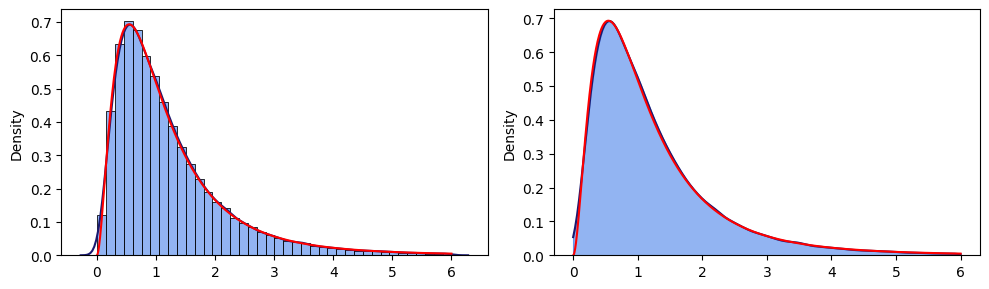

In [21]:
fig, ax = plt.subplots(1, 2)
plt.rcParams["figure.figsize"] = [10, 3]
plt.rcParams["figure.autolayout"] = True

F_stat_clipped = F_stat [F_stat < 6] #cutting off a few extreme values for a nicer-looking plot.

# Empirical density of the simulated statistic.
sns.histplot(x=F_stat_clipped, stat='density', bins=40, alpha=.7, color='cornflowerblue', ax=ax[0])
sns.kdeplot(x=F_stat_clipped, color='midnightblue', ax=ax[0])

# Theoretical F(dfn=df1, dfd=df2) density.
x_values = np.linspace(0.001, 6, 1000)
y_values = sp.stats.f.pdf(x=x_values, dfn=df1, dfd=df2)
sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[0])

sns.kdeplot(x=F_stat_clipped, color='cornflowerblue', ax=ax[1], fill=True, alpha=.7, clip=[0, 6])
sns.kdeplot(x=F_stat_clipped, color='midnightblue', ax=ax[1], clip=[0, 6])
sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[1]);

In [22]:
# Comparing empirical vs theoretical moments.
# mean = df2/(df2-2) for df2>2 ; variance = 2*df2^2*(df1+df2-2) / (df1*(df2-2)^2*(df2-4)) for df2>4.
(F_stat.mean(), df2 / (df2 - 2)), (F_stat.var(ddof=1), 2 * df2**2 * (df1 + df2 - 2) / (df1 * (df2 - 2)**2 * (df2 - 4)))

((np.float64(1.2787860577617356), 1.2857142857142858),
 (np.float64(1.529566819667995), 1.4326530612244899))

Once more, the empirical density (blue) overlays the theoretical $F_{\text{dfn}=\text{df}_1,\,\text{dfd}=\text{df}_2}$ density (red) closely, and the empirical mean and variance are close to the theoretical ones.